# Fase 3 — Entrenamiento y versionado del modelo

El objetivo es estimar el cierre de frío del día calendario siguiente. Cada fila conserva la fecha de emisión **D** y `y` representa el cierre de **D+1**.

- **Train** ajusta los modelos y la escala de Ridge.
- **Validation** compara alternativas y elige por MAE.
- **Test** se evalúa luego de congelar la elección y reentrenar con Train y Validation.

Usamos los CSV y las huellas de la Fase 2. El script y la notebook comparten las mismas funciones.

In [1]:
import sys  # Permite importar el código desde notebooks/ o desde la raíz.
from pathlib import Path  # Construye las rutas a los datos y resultados.
from tempfile import TemporaryDirectory  # Guarda una reproducción aislada del log.

import matplotlib.pyplot as plt  # Grafica las predicciones y los residuos.
import pandas as pd  # Arma las tablas de resultados.
from IPython.display import display  # Muestra tablas con encabezados en Jupyter.
from sklearn.inspection import permutation_importance  # Mide el aporte de cada variable en Validation.

raiz = Path.cwd()  # Identifica desde dónde se abrió la notebook.
if raiz.name == "notebooks":  # Si estamos en notebooks/, subimos a la raíz.
    raiz = raiz.parent  # La carpeta src está al lado de notebooks.
if str(raiz) not in sys.path:  # Agrega la raíz solo si todavía falta.
    sys.path.insert(0, str(raiz))  # Habilita los imports de este proyecto.

# Importamos las mismas funciones que usa la ejecución por terminal.
from src.train_model import BUSQUEDA, SEMILLA, comparar_modelos, leer_csv_verificado, leer_json

print("Semilla de los estimadores:", SEMILLA)  # Deja visible el control de aleatoriedad.

Semilla de los estimadores: 42


## 3.1 · Baselines y modelos

**Persistencia** predice que mañana se consumirá lo mismo que hoy. La **media móvil de siete días** suaviza variaciones de un día particular. Usa la ventana calendario que termina en D y la regla de cobertura de la Fase 2, con un mínimo de cuatro cierres válidos. El script comprueba que ambas referencias tengan un pronóstico para cada fecha evaluada.

| Modelo | Qué aprende | Qué ajustamos |
|---|---|---|
| Ridge | Una combinación lineal de las predictoras. La penalización L2 reduce coeficientes grandes, algo útil para variables relacionadas como las medias móviles. | Intensidad de regularización `alpha`. La escala se ajusta dentro del pipeline. |
| Random Forest | Promedia árboles entrenados con distintas muestras. Captura relaciones no lineales e interacciones. | Profundidad, tamaño mínimo de hoja y criterio de error. |
| XGBoost | Suma árboles pequeños en secuencia. Cada árbol ayuda a corregir el error de los anteriores. | Cantidad y profundidad de árboles, tasa de aprendizaje y función de pérdida. |
| LightGBM | También agrega árboles en secuencia y agrupa valores de las variables en histogramas. | Cantidad de árboles, hojas, tasa de aprendizaje, mínimo de observaciones y pérdida. |

Probamos las 12 columnas de Fase 2 y dos variantes para discutir la redundancia de las medias. Las variantes conservan 3 y 14 días, o solo 14 días. La media del baseline se sigue calculando en todas. El clima histórico permanece como diagnóstico hasta verificar que los valores puedan obtenerse al momento de pronosticar.

## 3.2 · Espacio de búsqueda y registro

Probamos combinaciones fijadas de antemano para que el análisis sea acotado y cada decisión pueda rastrearse. Cada ajuste se registra automáticamente con sus parámetros, partición, fechas, cantidad de filas y métricas. Esta notebook genera su propio log temporal al reproducir la comparación. El comando del README conserva el log oficial en `results/experiment_logs.csv`.

El **MAE** promedia los errores absolutos y es el criterio de selección de la consigna. El **RMSE** aumenta la influencia de los errores grandes. **R²** mide la mejora cuadrática frente a usar la media del target.

In [2]:
for familia, configuraciones in BUSQUEDA.items():  # Recorre el espacio de cada familia.
    print(familia, "-", len(configuraciones), "configuraciones")  # Resume el tamaño de búsqueda.
    display(pd.DataFrame(configuraciones))  # Permite revisar los parámetros exactos.

with TemporaryDirectory(prefix="tpf-modelado-") as temporal:  # Aísla el log de esta reproducción.
    baselines, pruebas, mejor, diagnostico = comparar_modelos(Path(temporal))  # Ajusta en Train y mide en Validation.
    log_reproducido = pd.read_csv(Path(temporal) / "results" / "experiment_logs.csv")  # Lee el log creado.
    assert log_reproducido["particion"].eq("validation").all()  # Comprueba la partición de todas las filas.

print("Cantidad de ajustes candidatos:", len(pruebas))  # Cuenta las combinaciones comparadas.
display(baselines.round(2))  # Presenta las dos referencias dentro de Validation.

Ridge - 6 configuraciones


,alpha
0,0.1
1,1.0
2,10.0
3,50.0
4,150.0
5,400.0


Random Forest - 4 configuraciones


,n_estimators,max_depth,min_samples_leaf,criterion
0,200,4,8,squared_error
1,200,8,6,squared_error
2,200,12,3,squared_error
3,200,5,10,absolute_error


XGBoost - 4 configuraciones


,n_estimators,max_depth,learning_rate,objective
0,120,2,0.05,reg:squarederror
1,180,3,0.04,reg:squarederror
2,120,2,0.05,reg:absoluteerror
3,180,3,0.04,reg:absoluteerror


LightGBM - 4 configuraciones


,n_estimators,num_leaves,learning_rate,min_child_samples,objective
0,120,7,0.05,18,regression
1,180,15,0.04,18,regression
2,120,7,0.05,18,regression_l1
3,180,15,0.04,18,regression_l1


Cantidad de ajustes candidatos: 54


,modelo,mae,rmse,r2
0,Persistencia,2727.13,3362.14,0.22
1,Media móvil de 7 días,2395.32,3145.88,0.31


## 3.3 · Comparación y diagnóstico en Validation

El mejor modelo se elige por el menor MAE entre las configuraciones. Si el MAE coincide a la precisión del registro, preferimos el grupo con menos variables. La tabla muestra la mejor combinación de cada familia y la mejor corrida de cada variante.

Definimos el **residuo** como valor real menos pronóstico. Un residuo positivo indica que el modelo se quedó corto. La diagonal del gráfico representa una predicción exacta. La media de residuos indica sesgo y el MAE mensual ayuda a ver si el error cambia durante el año.

In [3]:
metricas = ["modelo", "variante", "n_columnas", "mae", "rmse", "r2"]  # Columnas que se comparan.
por_familia = pruebas.drop_duplicates("modelo")[metricas].reset_index(drop=True)  # Primer lugar por familia.
por_variante = pruebas.drop_duplicates("variante")[metricas].reset_index(drop=True)  # Primer lugar por variante.
display(por_familia.round(2))  # Compara los cuatro modelos exigidos.
display(por_variante.round(2))  # Mide el efecto de reducir las ventanas.
print("Elección:", mejor["modelo"], "|", mejor["variante"], "|", mejor["hiperparametros"])  # Guarda el criterio.

,modelo,variante,n_columnas,mae,rmse,r2
0,Ridge,Fase 2 completa,12,2149.43,2790.71,0.46
1,Random Forest,Medias 3 y 14,11,2300.33,2871.57,0.43
2,XGBoost,Fase 2 completa,12,2300.50,2904.68,0.42
3,LightGBM,Fase 2 completa,12,2404.29,2965.39,0.39


,modelo,variante,n_columnas,mae,rmse,r2
0,Ridge,Fase 2 completa,12,2149.43,2790.71,0.46
1,Ridge,Medias 3 y 14,11,2161.15,2791.53,0.46
2,Ridge,Solo media 14,10,2187.58,2793.28,0.46


Elección: Ridge | Fase 2 completa | {'alpha': 10}


Residuo medio en Validation: -202.66 kW


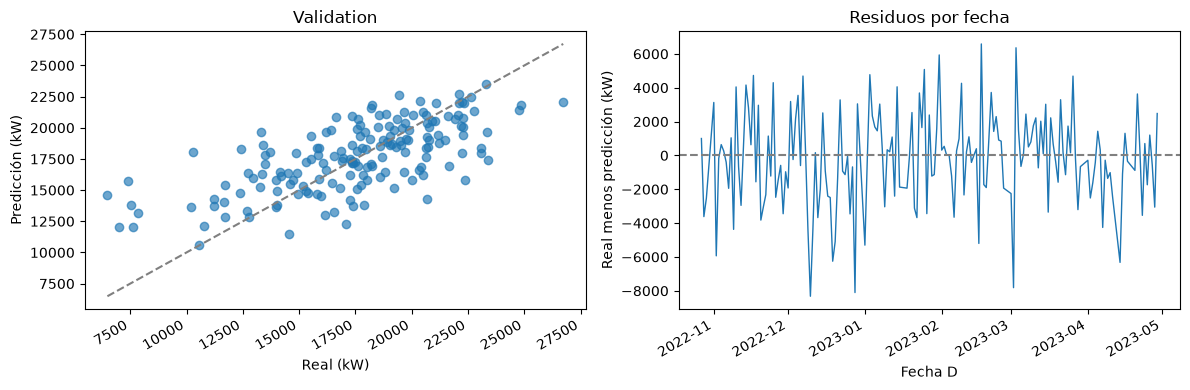

,filas,sesgo,mae
mes,,,
2022-10,3,-1717.54,2383.36
2022-11,30,-228.71,2259.50
2022-12,29,-1219.39,2804.32
2023-01,29,517.61,2394.69
2023-02,26,243.40,1656.68
2023-03,29,404.36,1917.06
2023-04,25,-813.74,1727.10


In [4]:
checksums = leer_json(raiz / "data" / "checksums.json")  # Carga las huellas de Fase 2.
val = leer_csv_verificado("validation.csv", checksums)  # Recupera las fechas y etiquetas de Validation.
columnas = mejor["columnas"]  # Usa el mismo conjunto elegido por MAE.
prediccion = diagnostico.predict(val[columnas])  # Predice las fechas reservadas para decidir.
residuo = val["y"] - prediccion  # Calcula cuánto faltó o sobró en cada pronóstico.
print(f"Residuo medio en Validation: {residuo.mean():.2f} kW")  # Resume el sesgo.

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))  # Prepara los dos gráficos.
ejes[0].scatter(val["y"], prediccion, alpha=0.65)  # Dibuja el valor real y el pronóstico de cada día.
minimo = min(val["y"].min(), prediccion.min())  # Fija el extremo inferior de la diagonal.
maximo = max(val["y"].max(), prediccion.max())  # Fija el extremo superior de la diagonal.
ejes[0].plot([minimo, maximo], [minimo, maximo], linestyle="--", color="gray")  # Referencia de error cero.
ejes[0].set(xlabel="Real (kW)", ylabel="Predicción (kW)", title="Validation")  # Identifica ambos ejes.
ejes[1].plot(val.index, residuo, linewidth=1)  # Permite ver errores persistentes por fecha.
ejes[1].axhline(0, color="gray", linestyle="--")  # Marca el valor de error cero.
ejes[1].set(xlabel="Fecha D", ylabel="Real menos predicción (kW)", title="Residuos por fecha")  # Agrega unidades.
fig.autofmt_xdate()  # Hace legibles las fechas.
fig.tight_layout()  # Evita superponer los títulos.
plt.show()  # Muestra los gráficos en el notebook.

mensual = pd.DataFrame({"residuo": residuo, "error_absoluto": residuo.abs()})  # Prepara los dos resúmenes.
mensual["mes"] = mensual.index.to_period("M")  # Agrupa por mes y año sin mezclar temporadas.
tabla_mensual = mensual.groupby("mes").agg(filas=("residuo", "size"), sesgo=("residuo", "mean"),
                                           mae=("error_absoluto", "mean"))  # Resume la cobertura y el error.
display(tabla_mensual.round(2))  # Permite identificar los períodos de mayor error.

### Importancia de las variables

Mezclamos los valores de una columna de Validation manteniendo las demás y medimos cuánto sube el MAE. Repetimos diez veces por columna. Una subida grande indica que el modelo usa la señal de esa variable en este tramo. Las predictoras correlacionadas pueden compartir señal y el resultado se interpreta en conjunto con la comparación de ventanas.

In [5]:
importancia = permutation_importance(  # Evalúa cuánto cambia el MAE al mezclar cada columna.
    diagnostico, val[columnas], val["y"], scoring="neg_mean_absolute_error",  # Usa únicamente Validation.
    n_repeats=10, random_state=SEMILLA, n_jobs=1,  # Repite con la semilla fijada.
)
tabla_importancia = pd.DataFrame({  # Guarda el promedio y el desvío de las repeticiones.
    "variable": columnas,  # Conserva los nombres usados en el ajuste.
    "aumento_mae_kw": importancia.importances_mean,  # Un valor positivo indica que mezclar empeora el modelo.
    "desvio_kw": importancia.importances_std,  # Expresa la variación entre mezclas.
}).sort_values("aumento_mae_kw", ascending=False)  # Ordena desde el mayor aumento de error.
display(tabla_importancia.round(2))  # Muestra la importancia relativa de las variables.

,variable,aumento_mae_kw,desvio_kw
8,frio_roll_mean_14,209.48,34.63
11,bodega_x_calor_estacional,125.48,31.61
2,KW Linea 3_Totalizadores Energia,73.15,19.26
5,frio_hoy_d,72.67,39.17
9,frio_diff_1,57.57,27.98
7,frio_roll_mean_7,39.98,24.88
6,frio_roll_mean_3,38.64,27.75
3,Red Paste L4_Consolidado Agua,30.36,20.36
1,KW Secador Kaeser_Totalizadores Energia,21.25,17.87
0,ET Servicios (Mj)_Consolidado GasVapor,5.73,11.94


## 3.4 · Reentrenamiento, Test y versión

Después de la elección se conserva el preparador de Fase 2 que produjo las variables. El estimador y su escala se vuelven a ajustar con las 969 filas de Train + Validation. El script evalúa el modelo final y los dos baselines sobre el mismo Test y guarda la tabla del informe. El artefacto serializado guarda el estimador, el preparador y las columnas en su orden de entrenamiento.

La evaluación se ejecuta desde la terminal como paso de cierre. Esta celda consulta el resultado ya guardado para conservar el protocolo de Test.

In [6]:
ruta_final = raiz / "results" / "evaluacion_final.json"  # Ubicación de la evaluación ya realizada.
if ruta_final.exists():  # La tabla existe después de evaluar una vez el modelo congelado.
    evaluacion = leer_json(ruta_final)  # Lee solamente los agregados guardados.
    tabla_final = pd.DataFrame.from_dict(evaluacion["metricas"], orient="index")  # Junta los tres pronósticos.
    print("Versión:", evaluacion["version"], "| Fechas evaluadas:", evaluacion["filas_test"])  # Muestra cobertura.
    display(tabla_final.round(2))  # Presenta las métricas del Test local.
else:  # Durante la selección todavía falta la evaluación final.
    print("El resultado de Test aparecerá después del cierre desde el script.")  # Explica el estado.

El resultado de Test aparecerá después del cierre desde el script.
